Dataset:
   Area_sqft  Bedrooms  Bathrooms  Age_years  Distance_to_city_km  Price_lakhs
0        824         2          2         16                 13.5        18.00
1       2159         3          3          4                  8.6        83.07
2       1926         3          3          9                 19.5        56.59
3       1505         2          2         17                 16.9        39.30
4       1494         3          3          9                 10.0        56.01

--- SIMPLE LINEAR REGRESSION ---
R2 Score: 0.751908538137878
RMSE: 12.470462132417525

--- MULTIPLE LINEAR REGRESSION ---
R2 Score: 0.7830866024342821
RMSE: 11.660571258122562

--- MODEL DETAILS ---
Coefficients: [ 0.02962978 -1.43046049  7.61906108 -0.33620223 -0.90770705]
Intercept: 11.250372566798283


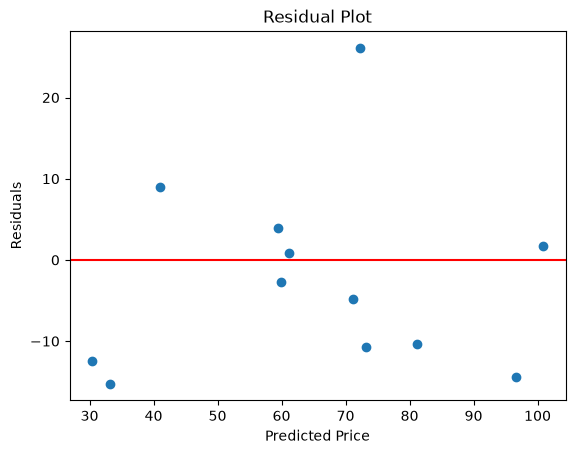

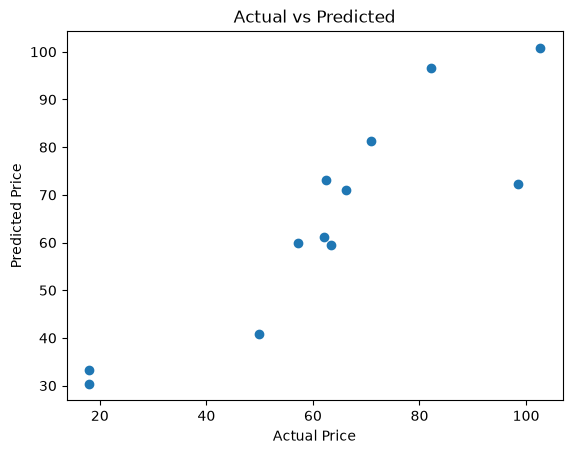

In [7]:

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# 2. Load Excel dataset
df = pd.read_excel("Housing_Price_Dataset_DAV.xlsx")

print("Dataset:")
print(df.head())

# 3. Select input and output columns
X = df[['Area_sqft', 'Bedrooms', 'Bathrooms',
        'Age_years', 'Distance_to_city_km']]

y = df['Price_lakhs']

# 4. Simple Linear Regression
X_simple = df[['Area_sqft']]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)

simple_pred = simple_model.predict(X_test_s)

print("\n--- SIMPLE LINEAR REGRESSION ---")
print("R2 Score:", r2_score(y_test_s, simple_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test_s, simple_pred)))

# 5. Multiple Linear Regression
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

multiple_pred = multiple_model.predict(X_test)

print("\n--- MULTIPLE LINEAR REGRESSION ---")
print("R2 Score:", r2_score(y_test, multiple_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, multiple_pred)))

# 6. Model Building
print("\n--- MODEL DETAILS ---")
print("Coefficients:", multiple_model.coef_)
print("Intercept:", multiple_model.intercept_)

# 7. Assumption Checking - Residual Plot
residuals = y_test - multiple_pred

plt.scatter(multiple_pred, residuals)
plt.axhline(y=0, color='red')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

# 8. Actual vs Predicted Graph
plt.scatter(y_test, multiple_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted")
plt.show()
